<a href="https://colab.research.google.com/github/pdtarricone/analytics_portfolio/blob/PDT_Analytics_Portfolio/Linear_Regression_V2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# to load and manipulate data
import pandas as pd
import numpy as np

# to visualize data
import matplotlib.pyplot as plt
import seaborn as sns

# to split the data into train and test sets
from sklearn.model_selection import train_test_split

# to build a linear regression model
from sklearn.linear_model import LinearRegression

# to check a regression model's performance
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

In [3]:
# let colab access my google drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
insurance = pd.read_csv('/content/drive/MyDrive/insurance_charges.csv')

In [7]:
insurance.head()

,age,children,smoker,region,plan,charges
0,19,0,yes,southwest,Silver,11788.66
1,18,1,no,southeast,Bronze,6483.12
2,28,3,no,southeast,Silver,6156.17
3,33,0,no,northwest,Gold,6550.05
4,32,0,no,northwest,Bronze,10362.04


In [8]:
# creating a copy of the data
data = insurance.copy()

In [9]:
data.shape

(1338, 6)

In [10]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   children  1338 non-null   int64  
 2   smoker    1338 non-null   object 
 3   region    1338 non-null   object 
 4   plan      1338 non-null   object 
 5   charges   1338 non-null   float64
dtypes: float64(1), int64(2), object(3)
memory usage: 62.8+ KB


In [11]:
data.describe()

,age,children,charges
count,1338.000000,1338.000000,1338.000000
mean,39.207025,1.094918,9852.747511
std,14.049960,1.205493,3588.235727
min,18.000000,0.000000,500.000000
25%,27.000000,0.000000,7298.795000
50%,39.000000,1.000000,9933.295000
75%,51.000000,2.000000,12479.195000
max,64.000000,5.000000,20453.480000


In [12]:
data.isnull().sum()

,0
age,0
children,0
smoker,0
region,0
plan,0
charges,0


In [13]:
# checking for duplicate values
data.duplicated().sum()

np.int64(0)

Univariate Analysis

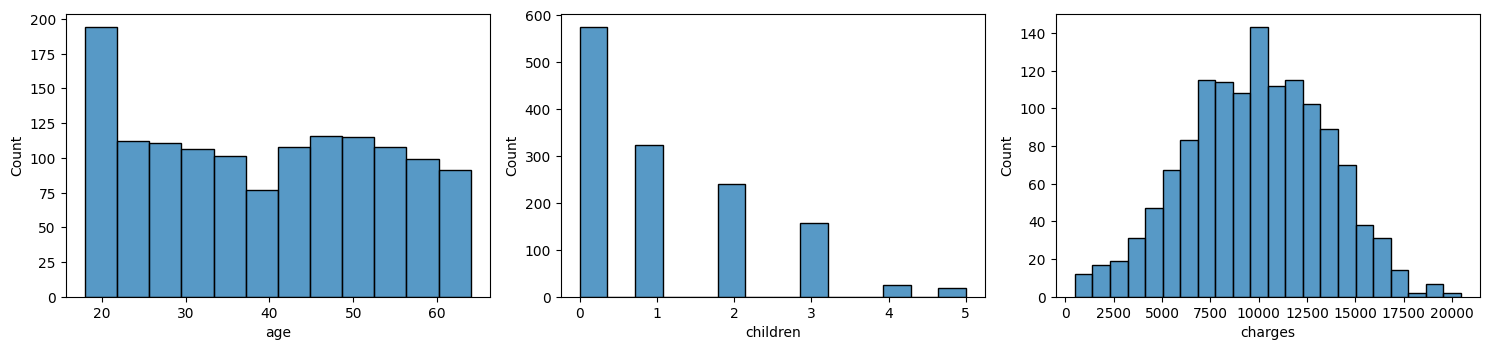

In [14]:
# defining the figure size
plt.figure(figsize=(15, 10))

# defining the list of numerical features to plot
features = data.select_dtypes(include=['number']).columns.tolist()

# creating the histograms
for i, feature in enumerate(features):
    plt.subplot(3, 3, i+1)    # assign a subplot in the main plot
    sns.histplot(data=data, x=feature)    # plot the histogram

plt.tight_layout()    # to add spacing between plots
plt.show()

**Observations:**
* **Age:** ranges from 18 to 64. There is a pronounced spike at ages 18 and 19 (about 69 policyholders each, against no more than 29 at any other age), and the remaining ages are spread fairly evenly up to 64.
* **Children:** most policyholders have 0 to 2 dependents, and very few have 4 or 5.
* **Charges (target variable):** values span roughly 500 to 20,500, with a mean of about 9,850 and a median close to 9,930. The distribution is bell-shaped and broadly symmetric, with a small group of low-cost policies on the left and only a thin upper tail beyond about 17,500 (just 12 policies).

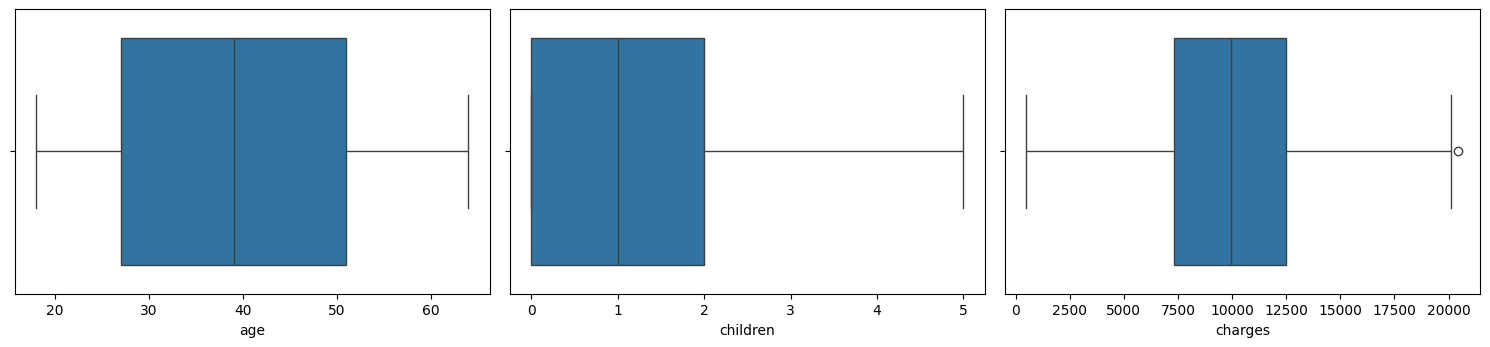

In [16]:
# defining the figure size
plt.figure(figsize=(15, 10))

# defining the list of numerical features to plot
features = data.select_dtypes(include=['number']).columns.tolist()

# creating the histograms
for i, feature in enumerate(features):
    plt.subplot(3, 3, i+1)    # assign a subplot in the main plot
    sns.boxplot(data=data, x=feature)    # plot the histogram

plt.tight_layout()    # to add spacing between plots
plt.show()

**Observations:**
* Age and children have no points beyond the whiskers.
* Charges has just one point beyond the upper whisker (about 20,450).

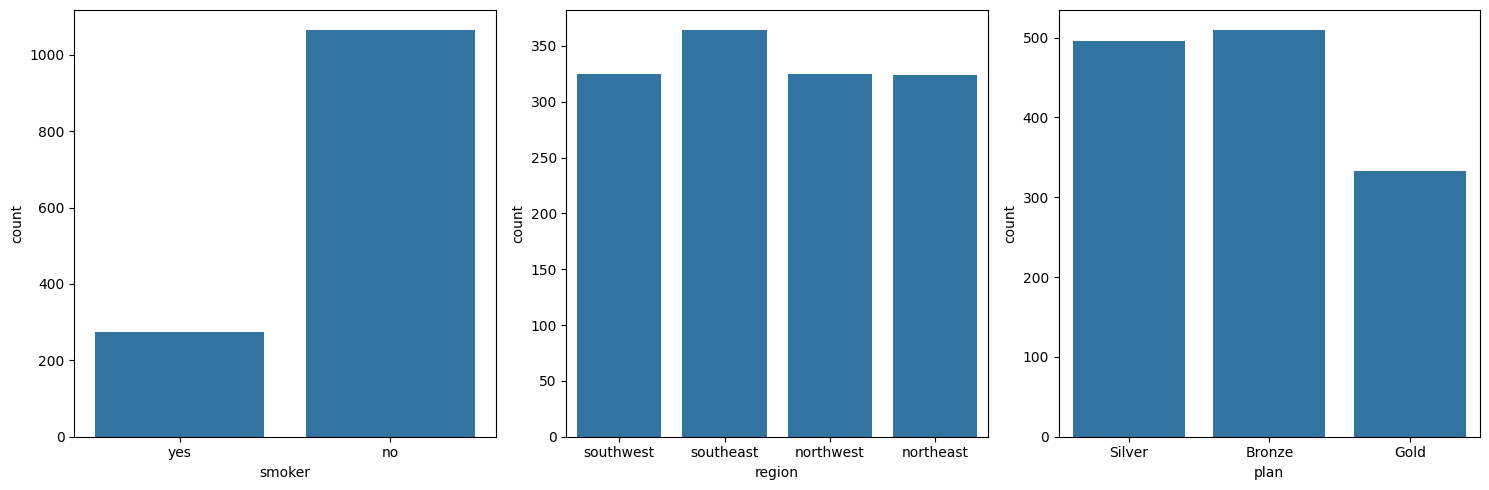

In [17]:
# defining the figure size
plt.figure(figsize=(15, 5))

# defining the list of categorical features to plot
features = data.select_dtypes(exclude=['number']).columns.tolist()

# creating the histograms
for i, feature in enumerate(features):
    plt.subplot(1, 3, i+1)    # assign a subplot in the main plot
    sns.countplot(data=data, x=feature)    # plot the histogram

plt.tight_layout()    # to add spacing between plots
plt.show()

**Observations:**
* **Smoker:** non-smokers make up roughly 80 percent of the sample and smokers roughly 20 percent, an approximate 4 to 1 ratio. The class imbalance is worth noting, but smoker status is expected to be one of the most informative predictors of medical charges.
* **Region:** the four regions are fairly evenly represented, with the southeast slightly larger.
* **Plan:** Bronze is the most subscribed plan (about 509 policies), followed by Silver (about 496) and Gold (about 333). The Bronze-heavy mix is consistent with a price-sensitive customer base skewed towards the entry-level tier.

Bivariate Analysis

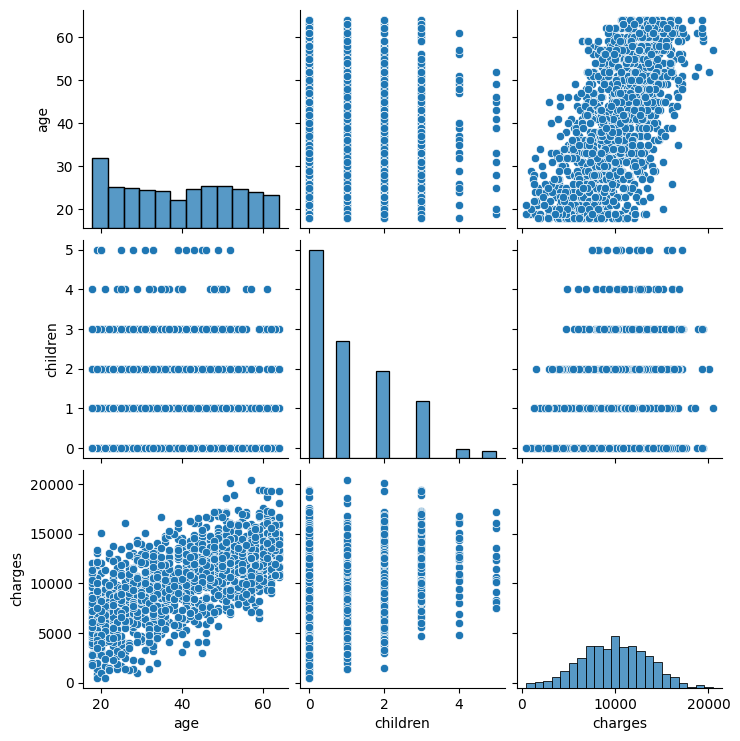

In [18]:
sns.pairplot(data);

**Observations:**
* Charges tend to increase with age, but at every age the charges are spread widely, which hints that other factors such as smoker status and plan type are layered on top of the age effect. We will confirm this in the multivariate model.
* Children takes only a few discrete values and shows only a weak relationship with charges.
* Age and children show no clear relationship with each other.

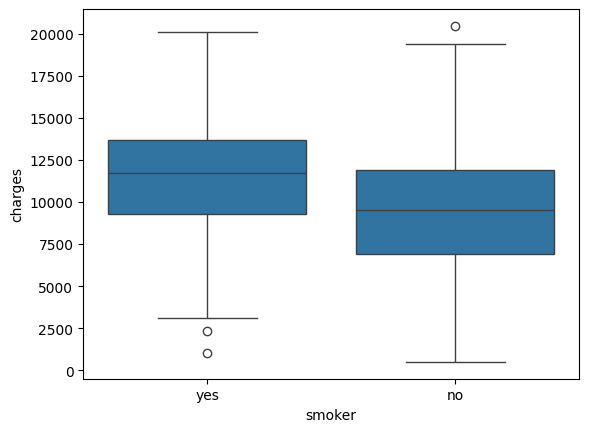

In [19]:
sns.boxplot(data=data, y='charges', x='smoker');

* Smokers are charged noticeably more than non-smokers on average, with median charges roughly 11,750 for smokers compared with about 9,500 for non-smokers.
* Smoker status is one of the strongest categorical drivers of the premium and needs to be carried into the model.

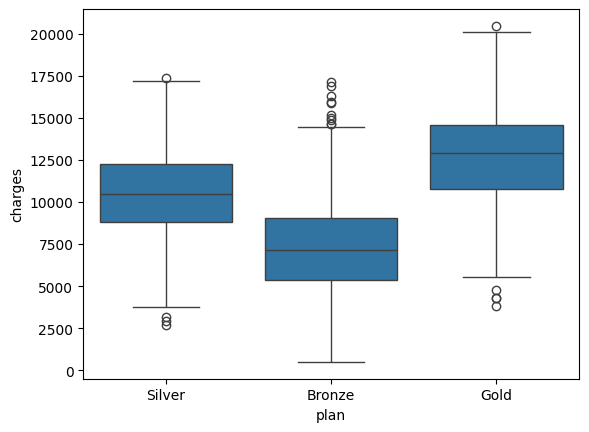

In [20]:
sns.boxplot(data=data, y='charges', x='plan');

**Observations:**
* Charges rise monotonically as we move from Bronze to Silver to Gold, with median charges of roughly 7,150 for Bronze, 10,500 for Silver, and 12,900 for Gold.
* Plan tier is a clean, monotonic driver of the premium and pairs well with individual risk features to explain overall charges.
* Seaborn lists the plans in order of appearance in the data (Silver, Bronze, Gold), not in tier order.


Correlation Heatmap

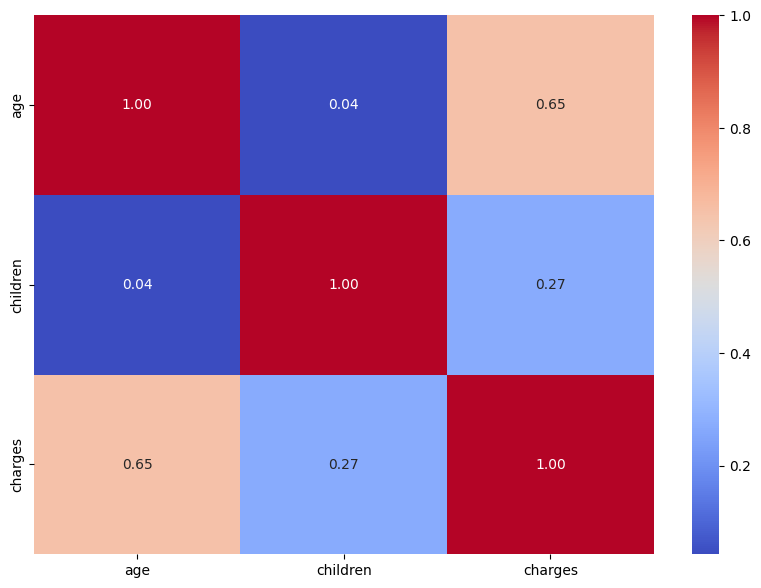

In [21]:
# defining the figure size
plt.figure(figsize=(10, 7))

# plotting the correlation heatmap
sns.heatmap(data.corr(numeric_only = True), annot=True, fmt='0.2f', cmap='coolwarm');

**Observations:**
* Age has the strongest positive correlation with charges at about 0.65, making it the dominant numerical driver.
* Children is only weakly correlated with charges at about 0.27, so it will help the model but will not carry it on its own.
* Age and children themselves are only weakly correlated with each other, so the two numerical predictors carry independent information.

Tain Test Split

Separate the independent variables (`X`) from the dependent variable (`y`) and then split the data into training and testing sets, with **80%** of the data used for training and **20%** for testing.

In [22]:
# defining the explanatory (independent) and response (dependent) variables
X = data.drop('charges', axis=1)
y = data['charges']

In [24]:
# splitting the data in 80:20 ratio for train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X,    # specifying the independent variables
    y,    # specifying the dependent variable
    test_size=0.20,    # specifying the size of the test set as a fraction of the whole data
    random_state=42    # specifying a seed value to enable reproducible results
)

Model Building

With the data split, begin the modelling phase using the `LinearRegression` class from `scikit-learn`. Linear regression estimates the linear relationship between the independent variables and the target variable and returns readable coefficients (`coef_`) and an intercept (`intercept_`) that we can connect to business language.

Build three models with different feature sets and then compare their predictive performance.







In the first model, use only the `age` feature to demonstrate how simple linear regression works and how it performs.

In [25]:
# defining the independent variable
ind_vars1 = ['age']

In [26]:
# creating an instance of the linear regression model
lin_reg1 = LinearRegression()

# fitting the model to the training data
lin_reg1.fit(X_train[ind_vars1], y_train)

LinearRegression()

In [27]:
# printing the linear regression coefficients
print(
    "Slope:", lin_reg1.coef_,
    "Intercept:", lin_reg1.intercept_,
)

Slope: [161.1101305] Intercept: 3600.2375556346824


In [28]:
# printing the linear regression equation
print(
    "charges =",
     "(", lin_reg1.coef_[0], ")", "*", ind_vars1[0],
    "+", lin_reg1.intercept_,
)

charges = ( 161.1101304965542 ) * age + 3600.2375556346824


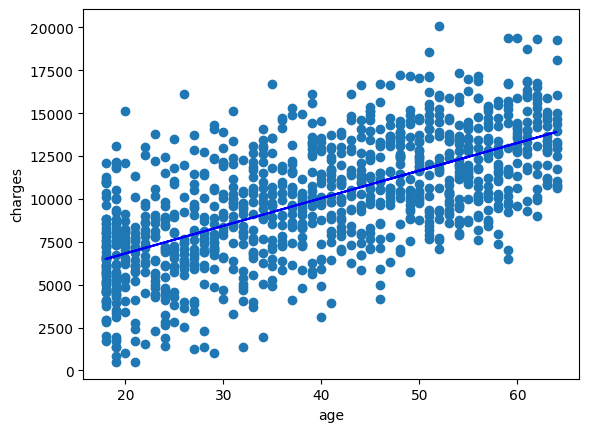

In [29]:
# plotting the best-fit line
fitted_values1 = lin_reg1.predict(X_train[ind_vars1])

# Plot the scatterplot and regression line
plt.scatter(X_train[ind_vars1], y_train)
plt.plot(X_train[ind_vars1], fitted_values1, color='blue')
plt.xlabel(ind_vars1[0])
plt.ylabel('charges')
plt.show()

**Observation:**
* **Slope = ~161.11**: each additional year of age is associated with an increase of ~161.11 in the predicted annual charge.
* **Intercept = ~3,600.24**: the predicted annual charge for a hypothetical policyholder of age 0. It is a mathematical anchor and not a business quantity.
* The best-fit line follows the upward trend between age and charges, but the wide vertical spread of points around the line shows that a single-feature model cannot explain most of the variation in charges.


Model 2

In [30]:
# defining the independent variables
ind_vars2 = ['age', 'children']

In [31]:
# creating an instance of the linear regression model
lin_reg2 = LinearRegression()

# fitting the model to the training data
lin_reg2.fit(X_train[ind_vars2], y_train)

LinearRegression()

In [32]:
# printing the linear regression coefficients
print(
    "Coefficients:", lin_reg2.coef_, lin_reg2.intercept_
)

Coefficients: [157.15059944 751.29711322] 2924.0288573042917


In [33]:
# printing the linear regression equation
print(
    "charges =",
    "(", lin_reg2.coef_[0], ")", "*", ind_vars2[0],
    "+ (", lin_reg2.coef_[1], ")", "*", ind_vars2[1],
    "+", lin_reg2.intercept_,
)

charges = ( 157.1505994376053 ) * age + ( 751.2971132219192 ) * children + 2924.0288573042917


**Observation:**
* **age coefficient = ~157.15**: each additional year of age is associated with an increase of ~157.15 in the predicted annual charge, holding `children` constant.
* **children coefficient = ~751.30**: each additional dependent is associated with an increase of ~751.30 in the predicted annual charge, holding age constant.
* **Intercept = ~2,924.03**, again a mathematical baseline rather than a business quantity.
* The model still ignores the strongest categorical drivers, smoker status and plan type.

Model 3

In [34]:
# creating one-hot encoded (also called dummy) variables
X = pd.get_dummies(
    X,    # defining the dataframe from where to fetch the data
    columns=X.select_dtypes(include=["object", "category"]).columns.tolist(),    # defining the type of columns for which dummies will be made
    drop_first=True,    # dropping the first dummy column
)

# specifying the datatype of the independent variables dataframe
X = X.astype(float)

X.head()

,age,children,smoker_yes,region_northwest,region_southeast,region_southwest,plan_Gold,plan_Silver
0,19.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0
1,18.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
2,28.0,3.0,0.0,0.0,1.0,0.0,0.0,1.0
3,33.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
4,32.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


**NOTE:**
* The dummy variables corresponding to the first category of each column (`smoker_no`, `region_northeast`, and `plan_Bronze`) have been dropped. They act as the reference categories for the coefficients of the encoded columns.
* We use **`astype(float)`** to guarantee that every independent variable is numerical, as `pd.get_dummies` may otherwise return Boolean values (`True` and `False`).

Since `X` now contains the encoded columns, we split the data again. Because we use the same `random_state`, the same rows are assigned to the training and testing sets as before, so all three models are evaluated on the same test data.


In [35]:
# splitting the data in 80:20 ratio for train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X,    # specifying the independent variables
    y,    # specifying the dependent variable
    test_size=0.20,    # specifying the size of the test set as a fraction of the whole data
    random_state=42    # specifying a seed value to enable reproducible results
)

In [36]:
# creating an instance of the linear regression model
lin_reg3 = LinearRegression()

# fitting the model to the training data
lin_reg3.fit(X_train, y_train)

LinearRegression()

In [37]:
# printing the linear regression coefficients
print(
    "Coefficients:", lin_reg3.coef_, lin_reg3.intercept_
)

Coefficients: [  130.55735016   500.99366437  2065.69716555  -607.75445046
  -615.9265618  -1373.97418497  2322.03661343  1005.24296096] 3498.814516053154


In [38]:
# printing the linear regression equation
equation = "charges = ( " + str(lin_reg3.coef_[0]) + " ) * " + X_train.columns.tolist()[0]

for i in range(1, lin_reg3.coef_.shape[0]):
    equation += " + ( " + str(lin_reg3.coef_[i]) + " ) * " + X_train.columns.tolist()[i]

equation +=  " + " + str(lin_reg3.intercept_)

print(equation)

charges = ( 130.55735016482677 ) * age + ( 500.9936643747901 ) * children + ( 2065.697165551574 ) * smoker_yes + ( -607.7544504605675 ) * region_northwest + ( -615.9265618048978 ) * region_southeast + ( -1373.9741849664315 ) * region_southwest + ( 2322.0366134307014 ) * plan_Gold + ( 1005.2429609595372 ) * plan_Silver + 3498.814516053154


**Observation:**
* **Intercept = ~3,498.81**: the mathematical baseline once all other features are set to zero (a non-smoker in the reference region on the reference plan).
* **Coefficient interpretation (each holding everything else constant):**
    * **age = ~130.56**: each additional year of age adds ~130.56 to the predicted charge. The effect is smaller than in Model 1 because part of what age was picking up is now attributed to plan and smoker.
    * **children = ~500.99**: each additional dependent adds ~500.99 to the predicted charge.
    * **smoker_yes = ~2,065.70**: smokers pay on average ~2,065.70 more than non-smokers of the same profile.
    * **plan_Gold = ~2,322.04** and **plan_Silver = ~1,005.24**: Gold policyholders pay ~2,322.04 more, and Silver policyholders ~1,005.24 more, than Bronze policyholders on the same profile.
    * **region_northwest = ~-607.75**, **region_southeast = ~-615.93**, **region_southwest = ~-1,373.97**: relative to the northeast (reference region), all three other regions have lower predicted charges, with the southwest being the cheapest.
* Among the categorical features, smoker status and the Gold plan carry the two largest effects on the predicted charge.

In insurance price prediction, the model can make two types of mistakes:

* **Underestimating the price**, when the predicted premium is lower than it should be.
* **Overestimating the price**, when the predicted premium is higher than it should be.

We use the following metrics to evaluate model performance:
- **RMSE (Root Mean Squared Error):** Square root of the mean of the squared errors; in the same unit as the target and sensitive to large errors; lower is better.
- **MAE (Mean Absolute Error):** Average absolute difference between the predictions and the actuals; in the same unit as the target; lower is better.
- **MAPE (Mean Absolute Percentage Error):** Average percentage deviation of predictions from actuals; lower is better.

In [39]:
# function to compute different metrics to check performance of a regression model
def model_performance_regression(model, predictors, target):
    """
    Function to compute different metrics to check regression model performance

    model: regression model
    predictors: independent variables
    target: dependent variable
    """

    # predicting using the independent variables
    pred = model.predict(predictors)

    rmse = np.sqrt(mean_squared_error(target, pred))  # to compute RMSE
    mae = mean_absolute_error(target, pred)  # to compute MAE
    mape = mean_absolute_percentage_error(target, pred)  # to compute MAPE

    # creating a dataframe of metrics
    df_perf = pd.DataFrame(
        {
            "RMSE": rmse,
            "MAE": mae,
            "MAPE": mape,
        },
        index=[0],
    )

    return df_perf

In [40]:
# checking the performance of the model on the training set
lin_reg1_train_perf = model_performance_regression(lin_reg1, X_train[ind_vars1], y_train)
lin_reg1_train_perf

,RMSE,MAE,MAPE
0,2710.465045,2169.290548,0.336613


In [41]:
# checking the performance of the model on the test set
lin_reg1_test_perf = model_performance_regression(lin_reg1, X_test[ind_vars1], y_test)
lin_reg1_test_perf

,RMSE,MAE,MAPE
0,2816.582339,2263.374106,0.378761


Model 1
**Observation:**
* Train and test errors are similar, with the test errors slightly higher (RMSE ~2,710.47 vs ~2,816.58, MAE ~2,169.29 vs ~2,263.37, MAPE ~0.34 vs ~0.38), so there is no sign of overfitting.
* RMSE and MAE are large relative to the mean charge of about 9,850, and a test MAPE of ~38 percent means the model is off by roughly that share of the actual charge on a typical prediction.
* The model is underfitting because it is working with only one feature.

In [42]:
# checking the performance of the model on the training set
lin_reg2_train_perf = model_performance_regression(lin_reg2, X_train[ind_vars2], y_train)
lin_reg2_train_perf

,RMSE,MAE,MAPE
0,2552.6266,2042.076687,0.311332


In [ ]:
# checking the performance of the model on the test set
lin_reg2_test_perf = model_performance_regression(lin_reg2, X_test[ind_vars2], y_test)
lin_reg2_test_perf

Model 2
**Observation:**
* Test RMSE has moved from ~2,816.58 in Model 1 to ~2,735.98 in Model 2, test MAE from ~2,263.37 to ~2,173.24, and test MAPE from ~0.38 to ~0.35. Adding `children` gives only a small improvement.
* Train and test errors remain similar, with the test errors slightly higher, so there is no sign of overfitting, but the model is still underfitting. To meaningfully close the gap we need to add the categorical features (`smoker`, `region`, `plan`).

In [43]:
# checking the performance of the model on the training set
lin_reg3_train_perf = model_performance_regression(lin_reg3, X_train, y_train)
lin_reg3_train_perf

,RMSE,MAE,MAPE
0,2233.80507,1774.35724,0.267291


In [44]:
# checking the performance of the model on the test set
lin_reg3_test_perf = model_performance_regression(lin_reg3, X_test, y_test)
lin_reg3_test_perf

,RMSE,MAE,MAPE
0,2236.49155,1752.241108,0.28526


Model 3

**Observation:**
* Train and test errors are close (RMSE ~2,233.81 vs ~2,236.49, MAPE ~0.27 vs ~0.29), which tells us the model generalises well and is not overfitting.
* Test RMSE has dropped to ~2,236.49 from ~2,735.98 in Model 2, and test MAE to ~1,752.24 from ~2,173.24.
* Test MAPE has fallen to ~0.29, so the typical prediction is off by ~29 percent of the actual charge, meaningfully better than the earlier two models.
* Adding the categorical features, particularly `smoker` and `plan`, is what closed most of the gap. This is now our best candidate model.


Model Performance Comparison

In [45]:
# training performance comparison
# concatenating all the training performance dataframes
models_train_comp_df = pd.concat(
    [
        lin_reg1_train_perf.T,
        lin_reg2_train_perf.T,
        lin_reg3_train_perf.T,
    ],
    axis=1,
)

# defining the list of models built
models_train_comp_df.columns = [
    "Simple Linear Regression - charges vs age",
    "Multiple Linear Regression - charges vs age, children",
    "Multiple Linear Regression - charges vs All independent variables",
]

print("Training performance comparison:")
models_train_comp_df.T

Training performance comparison:


,RMSE,MAE,MAPE
Simple Linear Regression - charges vs age,2710.465045,2169.290548,0.336613
"Multiple Linear Regression - charges vs age, children",2552.626600,2042.076687,0.311332
Multiple Linear Regression - charges vs All independent variables,2233.805070,1774.357240,0.267291


In [48]:
# compute the test performance for lin_reg2 to ensure it is defined in the environment
lin_reg2_test_perf = model_performance_regression(lin_reg2, X_test[ind_vars2], y_test)

# test performance comparison
# concatenating all the test performance dataframes
models_test_comp_df = pd.concat(
    [
        lin_reg1_test_perf.T,
        lin_reg2_test_perf.T,
        lin_reg3_test_perf.T,
    ],
    axis=1,
)

# defining the list of models built
models_test_comp_df.columns = [
    "Simple Linear Regression - charges vs age",
    "Multiple Linear Regression - charges vs age, children",
    "Multiple Linear Regression - charges vs All independent variables",
]

print("Test performance comparison:")
models_test_comp_df.T

Test performance comparison:


,RMSE,MAE,MAPE
Simple Linear Regression - charges vs age,2816.582339,2263.374106,0.378761
"Multiple Linear Regression - charges vs age, children",2735.983976,2173.243556,0.354951
Multiple Linear Regression - charges vs All independent variables,2236.491550,1752.241108,0.285260


**Observations:**
* **RMSE trajectory:** Test RMSE moves from ~2,816.58 in Model 1, to ~2,735.98 in Model 2, to ~2,236.49 in Model 3. The biggest single improvement comes from adding the categorical features in Model 3.
* **MAE trajectory:** Test MAE moves from ~2,263.37 in Model 1, to ~2,173.24 in Model 2, to ~1,752.24 in Model 3.
* **MAPE trajectory:** Test MAPE moves from ~0.38 in Model 1, to ~0.35 in Model 2, to ~0.29 in Model 3, matching the pattern seen in RMSE and MAE.
* **Overfitting check:** Train and test errors are close for Model 3, so the model is generalising well rather than memorising the training set.
* **Verdict:** Model 3 is the strongest performer across all three metrics and is the model we take forward for pricing prediction.

Business Insights

1. **Smoker status adds a large fixed premium.** After controlling for age, dependents, region, and plan, smokers pay **~2,066 more per year** than otherwise identical non-smokers. In the raw data, mean charges for smokers are about **11,533** versus **9,420** for non-smokers.

2. **Age drives a steady, cumulative cost effect.** Every additional year of age adds **~131 to the annual charge** in Model 3, and age is the strongest numerical predictor of charges (correlation of about **0.65** with charges).

3. **Plan tier translates cleanly into cost.** Median charges rise from about **7,150 (Bronze)** to **10,500 (Silver)** to **12,900 (Gold)**. In the model, Gold policyholders pay **~2,322 more** and Silver policyholders **~1,005 more** than Bronze holders of the same profile.

4. **Region matters less than lifestyle and plan.** The gap between the highest region (northeast, mean about **10,594**) and the lowest (southwest, mean about **9,104**) is only about 1,500, and in the model the southwest sits **~1,374 below** the northeast. Region is a useful adjustment but not a primary driver.

Business Recommendations

1. **Adopt Model 3 as the production pricing model.** It delivers a test RMSE of **~2,236** and a test MAPE of **~29 percent** on a mean charge near 9,850, which is accurate enough to move BluePeak from band-based pricing to individual risk-based pricing.

2. **Introduce a distinct smoker loading factor.** Given the **~2,066** annual cost differential, price smokers on a separate loading table and validate smoker declarations at underwriting to avoid non-disclosure risk.

3. **Refresh age curves in the underwriting engine.** Replace flat age bands with a continuous adjustment of **~131 per year of age**, so premiums step up smoothly year on year rather than jumping at band boundaries.

4. **Price plans in line with their observed cost curve.** Keep Bronze as the reference and price Silver **~1,005** above Bronze and Gold **~2,322** above Bronze on a like-for-like risk profile. Combined with the smoker and age adjustments above, this helps reduce cross-subsidy between low-risk and high-risk policyholders and materially lowers premium leakage on the portfolio.

Additional Multivariate Analysis

In [50]:
# Reload a fresh, unencoded copy of the dataset for appendix EDA
data_eda = pd.read_csv('/content/drive/MyDrive/insurance_charges.csv').drop_duplicates().reset_index(drop=True)
data_eda.head()

,age,children,smoker,region,plan,charges
0,19,0,yes,southwest,Silver,11788.66
1,18,1,no,southeast,Bronze,6483.12
2,28,3,no,southeast,Silver,6156.17
3,33,0,no,northwest,Gold,6550.05
4,32,0,no,northwest,Bronze,10362.04


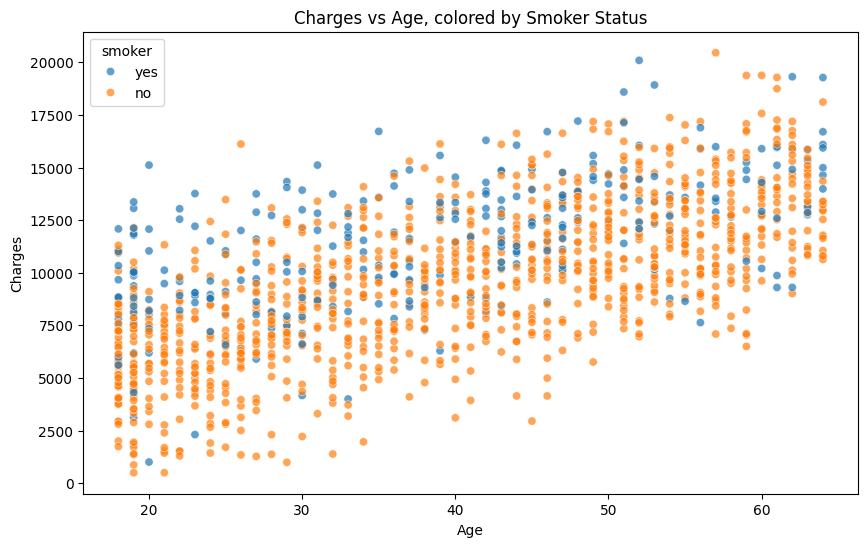

In [51]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='age', y='charges', hue='smoker', data=data_eda, alpha=0.7)
plt.title('Charges vs Age, colored by Smoker Status')
plt.xlabel('Age')
plt.ylabel('Charges')
plt.show()